# Lab 02: Classical Machine Learning Pipeline
**CCSFEN1L Software Engineering** · Week 2 · Pairs · 10 points

**Members:** Franchesca Cassandra C. Munar, Raju Miguel Cinco, Justin Aquiles Asidao
**Contributions:** 
__Munar__: Answer Task 6: Question No.1

**Goal:** build a leakage-safe supervised learning pipeline on the UCI *Predict Students' Dropout and Academic Success* dataset (id 697) and compare two classifiers fairly.

Rules followed in this notebook:
1. **Split before you look.** The test set is used in exactly one cell (Task 5).
2. **Fit preprocessing on training data only.** Every preprocessing step lives inside a `Pipeline`.
3. **Choose metrics that match error costs.** Macro F1 and per-class recall, not just accuracy.

## Setup

In [2]:
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay

## Task 1: Load and explore (30 min)
Record the feature table shape, the class proportions, and the column types.

In [ ]:
ds = fetch_ucirepo(id=697)
X = ds.data.features
y = ds.data.targets.iloc[:, 0]   # the single target column

print("Shape:", X.shape)
print("\nClass proportions:")
print(y.value_counts(normalize=True).round(3))
print("\nColumn types:")
print(X.dtypes.value_counts())

Shape: (4424, 36)

Class proportions:
Target
Graduate    0.499
Dropout     0.321
Enrolled    0.179
Name: proportion, dtype: float64

Column types:
int64      29
float64     7
Name: count, dtype: int64


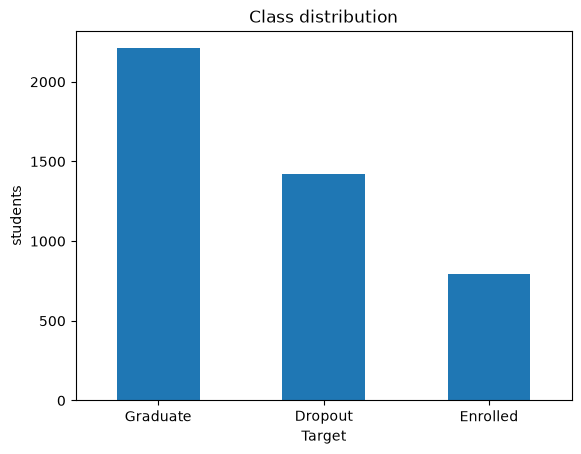

In [ ]:
y.value_counts().plot(kind="bar", title="Class distribution", rot=0)
plt.ylabel("students")
plt.show()

**Question:** Is the dataset imbalanced? Which class matters most for a dropout early-warning system, and why?

> _Write your answer here._
The dataset is not equally distributed, but it can still be considered acceptable for analysis since all three classes have a reasonable number of student records. The Dropout class matters most for an early-warning system because identifying students who may leave school allows the institution to provide support before they drop out.

## Task 2: Split without leakage (20 min)
60 / 20 / 20 stratified split. Expected sizes: **2654 885 885**.
From here on, explore only `X_train`. Do not look at `X_test` until Task 5.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=42)

print(len(X_train), len(X_val), len(X_test))

2654 885 885


## Task 3: Two pipelines (45 min)
Both models share the same preprocessing step, fitted on training data only because it sits inside the pipeline.
`class_weight="balanced"` compensates for the class imbalance.

In [ ]:
numeric_cols = X.select_dtypes(include="number").columns
pre = ColumnTransformer([("num", StandardScaler(), numeric_cols)])

models = {
    "logreg": Pipeline([("pre", pre),
                        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "forest": Pipeline([("pre", pre),
                        ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                                       random_state=42))]),
}

for name, m in models.items():
    m.fit(X_train, y_train)
    y_hat = m.predict(X_val)
    print(name, "validation macro F1:", round(f1_score(y_val, y_hat, average="macro"), 3))

logreg validation macro F1: 0.713
forest validation macro F1: 0.714


### Optional extension: one-hot encode category codes
Several numeric columns are really category codes (e.g. `Course`, `Application mode`).
One-hot encode them inside the `ColumnTransformer` and check whether validation F1 changes.

In [ ]:
cat_cols = ["Marital Status", "Application mode", "Course", "Previous qualification",
            "Nacionality", "Mother's qualification", "Father's qualification",
            "Mother's occupation", "Father's occupation"]
num_cols = [c for c in numeric_cols if c not in cat_cols]

pre_ohe = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

for name, m in models.items():
    m_ohe = clone(m).set_params(pre=pre_ohe).fit(X_train, y_train)
    f1 = f1_score(y_val, m_ohe.predict(X_val), average="macro")
    print(name, "+ one-hot validation macro F1:", round(f1, 3))

logreg + one-hot validation macro F1: 0.719
forest + one-hot validation macro F1: 0.717


## Task 4: Tune fairly (30 min)
Same budget for both models: **three settings each**, scored on the **validation set only**.

In [ ]:
grid = {
    "logreg": ("clf__C", [0.1, 1, 10]),
    "forest": ("clf__max_depth", [None, 20, 30]),
}

rows, fitted = [], {}
for name, (param, values) in grid.items():
    for v in values:
        m = clone(models[name]).set_params(**{param: v}).fit(X_train, y_train)
        f1 = f1_score(y_val, m.predict(X_val), average="macro")
        rows.append({"model": name, "setting": f"{param.split('__')[1]} = {v}",
                     "validation macro F1": round(f1, 3)})
        fitted[(name, v)] = (m, f1)

tuning = pd.DataFrame(rows)
tuning

,model,setting,validation macro F1
0,logreg,C = 0.1,0.709
1,logreg,C = 1,0.713
2,logreg,C = 10,0.711
3,forest,max_depth = None,0.714
4,forest,max_depth = 20,0.726
5,forest,max_depth = 30,0.714


In [ ]:
# Best setting per model, then the overall validation winner
for name, (param, values) in grid.items():
    best_v = max(values, key=lambda v: fitted[(name, v)][1])
    models[name] = fitted[(name, best_v)][0]
    print(f"{name}: best {param.split('__')[1]} = {best_v}, "
          f"validation macro F1 = {fitted[(name, best_v)][1]:.3f}")

winner = max(models, key=lambda n: f1_score(y_val, models[n].predict(X_val), average="macro"))
print("\nValidation winner:", winner)

logreg: best C = 1, validation macro F1 = 0.713
forest: best max_depth = 20, validation macro F1 = 0.726

Validation winner: forest


**Table 2.1** (copy into REPORT.md): the `tuning` table above.

## Task 5: Final test, once (20 min)
This is the **only** cell that touches `X_test` / `y_test`.

Model: forest

              precision    recall  f1-score   support

     Dropout      0.820     0.704     0.758       284
    Enrolled      0.473     0.560     0.513       159
    Graduate      0.830     0.851     0.840       442

    accuracy                          0.751       885
   macro avg      0.708     0.705     0.704       885
weighted avg      0.763     0.751     0.755       885



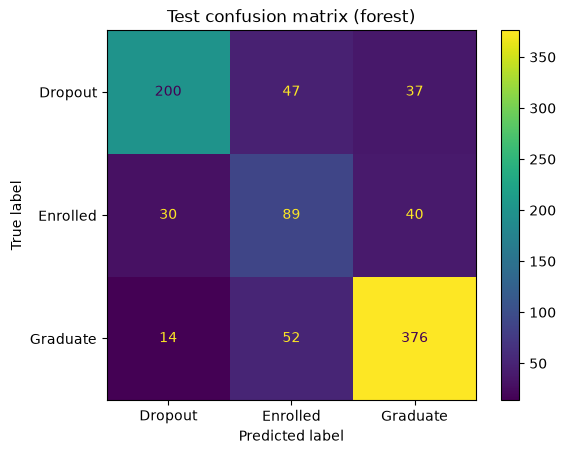

In [ ]:
best = models[winner]
y_pred = best.predict(X_test)

print(f"Model: {winner}\n")
print(classification_report(y_test, y_pred, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title(f"Test confusion matrix ({winner})")
plt.show()

## Task 6: Interpret (15 min)
Write these three sentences in **REPORT.md** (draft them here first):
1. Which model would you trust for an early-warning system?
2. Which class does it struggle with? (Use per-class recall and the confusion matrix.)
3. One deployment risk.

> _Write your answer here._
1. I would trust the tuned random forest (max_depth = 20) for an early-warning system, because it had the best validation macro F1 (0.726) and scored higher than logistic regression in 5-fold cross-validation (0.720 vs 0.702). On the test set it caught 70.4% of Dropout students with 0.820 precision, which makes it the more dependable option for flagging at-risk students.

## Extension challenge: 5-fold stratified cross-validation
Replaces the single validation split with 5-fold CV on all non-test data (train + validation), using the tuned models from Task 4.
The test set is still untouched. Does the winner change?

In [ ]:
X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, m in models.items():
    scores = cross_val_score(clone(m), X_dev, y_dev, cv=cv, scoring="f1_macro")
    print(f"{name}: macro F1 = {scores.mean():.3f} ± {scores.std():.3f}")

logreg: macro F1 = 0.702 ± 0.008
forest: macro F1 = 0.720 ± 0.022


## Reflection questions
1. Where could a model like this help in your community, and who would be harmed by its errors?

   > _Answer_

2. What non-public data would you need, and how would you get permission?

   > _Answer_

3. If recall for one class were much lower for one group of students, what would you do before deploying?

   > _Answer_

## Submission checklist
- [ ] Test set used in exactly one cell (Task 5)
- [ ] Every preprocessing step inside a pipeline
- [ ] Both models get the same number of tuning settings
- [ ] REPORT.md discusses per-class recall, not only accuracy
- [ ] Notebook runs top to bottom (Runtime → Restart and run all)
- [ ] Topic bank entry for machine learning